# Ejercicio 5: Reconstrucción en condiciones ideales

Tomamos una imagen de prueba de 8x8 (el "fantoma") y simulamos un tomógrafo: cada medición es la suma de los píxeles que atraviesa un rayo. Con esas sumas intentamos reconstruir la imagen.

Probamos con tres conjuntos de direcciones de rayos: 2 (horizontal y vertical), 4 (sumando las diagonales) y 7. Cuantas más direcciones, más mediciones y más información tenemos.

La celda de abajo arma la matriz de proyección de cada caso (cada fila es un rayo) y muestra su rango. El rango dice cuánta información independiente aportan las mediciones; lo que falta para llegar a 64 (la cantidad de píxeles) es la dimensión del espacio nulo, o sea, cuántas "direcciones" de la imagen los rayos no pueden ver.

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Importar todo lo anterior

X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    # Devuelve A (m x n^2) y la lista de pares ((alpha, beta), s) de cada fila.
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # np.unique ya devuelve ordenado
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas, dtype=float), info


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]


A2, _ = matriz_proyeccion(n, D2)
A4, _ = matriz_proyeccion(n, D4)
A7, _ = matriz_proyeccion(n, D7)
matrices = {2: A2, 4: A4, 7: A7}

for k, A in matrices.items():
    print(f"A{k}: {str(A.shape):>10}   rango = {np.linalg.matrix_rank(A):>2}   "
          f"dim Nul = {64 - np.linalg.matrix_rank(A):>2}")

A2:   (16, 64)   rango = 15   dim Nul = 49
A4:   (46, 64)   rango = 39   dim Nul = 25
A7:  (119, 64)   rango = 64   dim Nul =  0


## Inciso a)

Simulamos las mediciones multiplicando cada matriz por la imagen original (sin ruido). Después reconstruimos resolviendo el sistema por cuadrados mínimos con `lstsq`. Cuando hay muchas soluciones posibles, `lstsq` devuelve la de norma mínima.

In [11]:
reconstrucciones = {}
mediciones = {}

for k, A in matrices.items():
    b = A @ x_fantoma
    x_hat, residuos_lstsq, rango_lstsq, sv = np.linalg.lstsq(A, b, rcond=None)
    mediciones[k] = b
    reconstrucciones[k] = x_hat
    print(f"A{k}:  b de R^{b.shape[0]}   rango informado por lstsq = {rango_lstsq}")

A2:  b de R^16   rango informado por lstsq = 15
A4:  b de R^46   rango informado por lstsq = 39
A7:  b de R^119   rango informado por lstsq = 64


## Inciso b)

Para cada caso calculamos dos cosas:
- **Residuo**: qué tan bien la reconstrucción reproduce las mediciones.
- **Error relativo**: qué tan lejos quedó la reconstrucción de la imagen original.

In [12]:
encabezado = (f"{'k':>2} {'dim(A_k)':>11} {'rango':>6} {'dim Nul':>8} " f"{'||r_k||':>12} {'error rel.':>12}")
print(encabezado)
print("-" * len(encabezado))

# calculo de residuos r_k y error relativo
resumen = {}
for k, A in matrices.items():
    b = mediciones[k]
    x_hat = reconstrucciones[k]
    r = b - A @ x_hat
    norma_r = np.linalg.norm(r)
    err_rel = np.linalg.norm(x_hat - x_fantoma) / np.linalg.norm(x_fantoma)
    rango = np.linalg.matrix_rank(A)
    resumen[k] = (norma_r, err_rel, rango)
    print(f"{k:>2} {str(A.shape):>11} {rango:>6} {64 - rango:>8} " f"{norma_r:>12.3e} {err_rel:>12.3e}")

 k    dim(A_k)  rango  dim Nul      ||r_k||   error rel.
--------------------------------------------------------
 2    (16, 64)     15       49    4.263e-15    4.689e-01
 4    (46, 64)     39       25    1.623e-14    1.365e-01
 7   (119, 64)     64        0    1.532e-14    2.107e-15


## Inciso c)

Para cada caso mostramos la imagen original, la reconstruida y la diferencia entre ambas, todas con la misma escala de colores para poder compararlas.

escala de color común: [-0.220, 0.800]


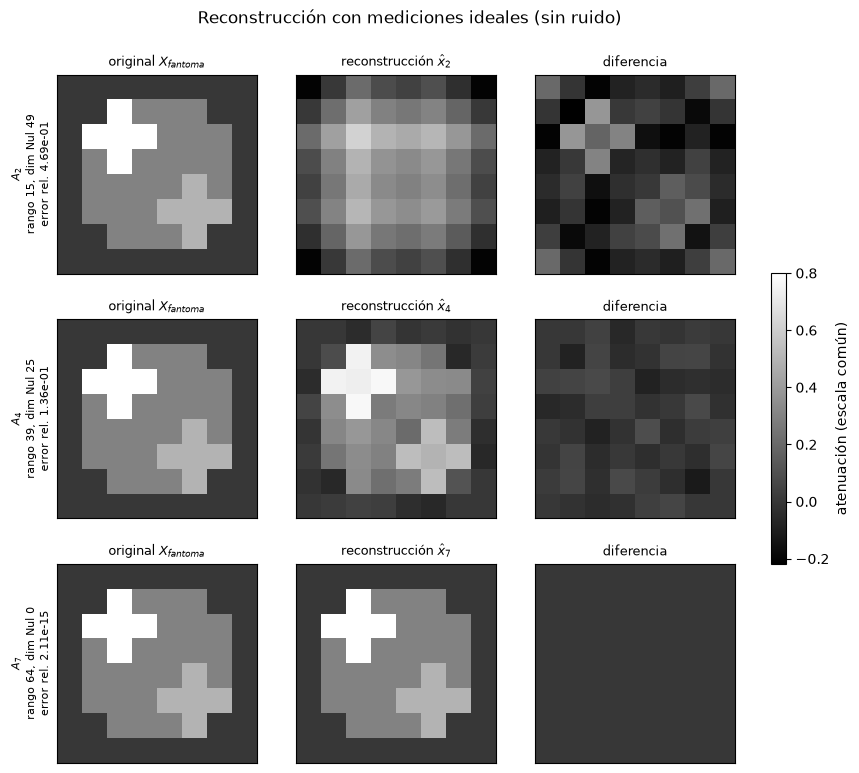

In [13]:
todos = [X_fantoma] + [reconstrucciones[k].reshape(n, n) for k in matrices] \
        + [(x_fantoma - reconstrucciones[k]).reshape(n, n) for k in matrices]
vmin = min(M.min() for M in todos)
vmax = max(M.max() for M in todos)
print(f"escala de color común: [{vmin:.3f}, {vmax:.3f}]")

fig, axes = plt.subplots(3, 3, figsize=(9.4, 9.0))
for fila, k in enumerate(matrices):
    X_hat = reconstrucciones[k].reshape(n, n)
    diferencia = X_fantoma - X_hat
    norma_r, err_rel, rango = resumen[k]

    paneles = [
        (X_fantoma, "original $X_{fantoma}$"),
        (X_hat, f"reconstrucción $\\hat{{x}}_{{{k}}}$"),
        (diferencia, "diferencia"),
    ]
    for col, (M, titulo) in enumerate(paneles):
        ax = axes[fila, col]
        im = ax.imshow(M, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(titulo, fontsize=9)
    axes[fila, 0].set_ylabel(f"$A_{{{k}}}$\nrango {rango}, dim Nul {64 - rango}\n"
                             f"error rel. {err_rel:.2e}", fontsize=8)
    axes[fila, 0].set_yticks([])

fig.colorbar(im, ax=axes, fraction=0.02, label="atenuación (escala común)")
fig.suptitle("Reconstrucción con mediciones ideales (sin ruido)", y=0.95)
plt.show()

Ahora graficamos solo las diferencias, cada una con su propia escala, para ver su forma aunque sean chicas.

NameError: name 'guardar' is not defined

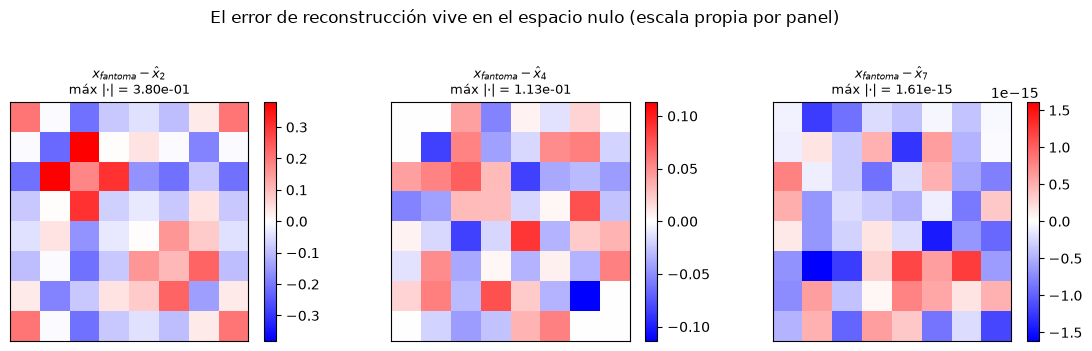

In [14]:
# Ampliamos las diferencias con su propia escala, para ver su ESTRUCTURA.
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.3))
for ax, k in zip(axes, matrices):
    diferencia = (x_fantoma - reconstrucciones[k]).reshape(n, n)
    lim = max(np.abs(diferencia).max(), 1e-16)
    im = ax.imshow(diferencia, cmap="bwr", vmin=-lim, vmax=lim)
    ax.set_title(f"$x_{{fantoma}} - \\hat{{x}}_{{{k}}}$\nmáx |·| = {lim:.2e}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("El error de reconstrucción vive en el espacio nulo (escala propia por panel)",
             y=1.05)
fig.tight_layout()
guardar(fig, "ejercicio_05c_diferencias")
plt.show()

##### ¿Por qué un residuo casi cero no garantiza recuperar la imagen?

El residuo solo mide si la reconstrucción es coherente con las mediciones, no si se parece a la imagen real. Si la matriz tiene espacio nulo, hay cambios en la imagen que los rayos no detectan: se puede sumar cualquiera de esos cambios y las mediciones dan igual. Por eso puede haber residuo cero y aun así una imagen distinta.

- **2 direcciones**: residuo casi cero pero error del 47%. Sale una imagen borrosa.
- **4 direcciones**: el error baja al 14%, pero quedan patrones que los rayos no ven.
- **7 direcciones**: no hay espacio nulo, la solución es única y se recupera la imagen exacta.

En resumen, un residuo chico solo asegura una buena reconstrucción si la matriz tiene rango completo.